# 0. Installations & Global Setup

In [1]:
# 0.1 Install Dependencies
!pip install -q scikit-posthocs keras-flops imagehash

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.4/46.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 7.4 MB/s eta 0:00:00


In [2]:
# 0.2 Global Setup & Imports
import os
import cv2
import time
import shutil
import random
import imagehash
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import layers
import tensorflow.keras.backend as K
from tensorflow.keras.applications import DenseNet121, MobileNetV2
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, accuracy_score
from scipy.stats import shapiro, f_oneway, kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import scikit_posthocs as sp
from tqdm.notebook import tqdm
from google.colab import drive
from PIL import Image

In [4]:

try:
    from keras_flops import get_flops
except Exception as e:
    print(f"Warning: keras_flops unavailable ({e}). FLOPs will be reported as 0.")
    get_flops = None

# 0.3 Constants & Paths
DRIVE_ZIP_PATH = "/content/drive/MyDrive/Thesis/Dataset/mendeley_raw_data.zip"
LOCAL_SOURCE_DIR = "/content/mendeley_raw_data/Laptop Components Image Dataset to Classify Different Components/Raw Data/Raw Data"
BASE_OUTPUT_DIR = "/content/structured_ewaste_pipeline"
CHECKPOINT_DIR = "/content/drive/MyDrive/Thesis/Model_Checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

DIR_TO_CLASS = {
    "5. Motherboard": "Motherboard",
    "1. Battery": "Battery",
    "8. RAM": "RAM",
    "11. WifiCard": "WiFi Card",
    "20. CPUFan": "CPU Fan"
}
TARGET_CLASSES = list(DIR_TO_CLASS.values())
SPLITS = ["train", "val", "test"]

# Hyperparameters
BLUR_THRESHOLD = 100.0 # <----- Needs to be 100
MIN_CLASS_SIZE = 120
VAL_TEST_SIZE = 0.20
RANDOM_STATE = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16

# 1. Environment Setup & Data Ingestion
## This cell connects to Drive and handles the high-speed local transfer.

In [7]:
# Mount Google Drive
drive.mount('/content/drive')

# Copy and extract dataset locally for faster I/O
!cp "{DRIVE_ZIP_PATH}" /content/
!unzip -q /content/mendeley_raw_data.zip -d /content/mendeley_raw_data

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Data Cleaning & Stratified Partitioning (ETL)
## This cell filters blurry images and executes the 80/10/10 stratified split across all 5 classes.

In [8]:
def calculate_laplacian_variance(image_path):
    image = cv2.imread(image_path)
    if image is None:
        return 0.0, False
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var(), True

def build_directory_structure():
    for split in SPLITS:
        for dir_name, component in DIR_TO_CLASS.items():
            os.makedirs(os.path.join(BASE_OUTPUT_DIR, split, component), exist_ok=True)

def process_and_split_dataset():
    dataset_records = []
    rejected_blurry = 0
    rejected_unreadable = 0

    for dir_name, component in DIR_TO_CLASS.items():
        component_dir = os.path.join(LOCAL_SOURCE_DIR, dir_name)
        if not os.path.exists(component_dir):
            continue

        filenames = [f for f in os.listdir(component_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

        for filename in tqdm(filenames, desc=component):
            file_path = os.path.join(component_dir, filename)
            blur_variance, read_ok = calculate_laplacian_variance(file_path)

            if not read_ok:
                rejected_unreadable += 1
                continue

            if blur_variance >= BLUR_THRESHOLD:
                dataset_records.append({"file_path": file_path, "label": component})
            else:
                rejected_blurry += 1

    df = pd.DataFrame(dataset_records)
    if df.empty:
        return None

    class_counts = df['label'].value_counts()
    for component, count in class_counts.items():
        if count < MIN_CLASS_SIZE:
            raise ValueError(f"Class '{component}' has only {count} valid images, falling below the required floor of {MIN_CLASS_SIZE}.")

    train_df, temp_df = train_test_split(df, test_size=VAL_TEST_SIZE, stratify=df['label'], random_state=RANDOM_STATE)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=RANDOM_STATE)

    partitions = [("train", train_df), ("val", val_df), ("test", test_df)]

    for split_name, partition_df in partitions:
        for _, row in tqdm(partition_df.iterrows(), total=len(partition_df), desc=split_name):
            src = row['file_path']
            dest = os.path.join(BASE_OUTPUT_DIR, split_name, row['label'], os.path.basename(src))
            shutil.copy2(src, dest)

    return df

build_directory_structure()
df = process_and_split_dataset()

Motherboard:   0%|          | 0/140 [00:00<?, ?it/s]

Battery:   0%|          | 0/140 [00:00<?, ?it/s]

RAM:   0%|          | 0/140 [00:00<?, ?it/s]

WiFi Card:   0%|          | 0/140 [00:00<?, ?it/s]

CPU Fan:   0%|          | 0/140 [00:00<?, ?it/s]

train:   0%|          | 0/560 [00:00<?, ?it/s]

val:   0%|          | 0/70 [00:00<?, ?it/s]

test:   0%|          | 0/70 [00:00<?, ?it/s]

# 3. TensorFlow Dataset Pipeline & Augmentation
## Creates the data generators and the dynamic augmentation layer.

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "train"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=True, seed=RANDOM_STATE
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "val"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_OUTPUT_DIR, "test"),
    labels="inferred", label_mode="categorical",
    class_names=TARGET_CLASSES, batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE, shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Data augmentation pipeline — matches Chapter 3 §3.9 / GEMINI.md Section 5 exactly:
# six transforms, train-partition only, applied dynamically per epoch.
# Rotation: +/-30deg | Horizontal flip only (no vertical flip) | Zoom: +/-15%
# Width/height shift: +/-10% | Brightness: +/-25% | Contrast: +/-20%
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(factor=(-30.0 / 360.0, 30.0 / 360.0)),
    layers.RandomZoom(height_factor=(-0.15, 0.15)),
    layers.RandomTranslation(height_factor=(-0.10, 0.10), width_factor=(-0.10, 0.10)),
    layers.RandomBrightness(factor=(-0.25, 0.25)),
    layers.RandomContrast(factor=0.20)
], name="e_waste_augmentation")


# 4. Loss Function, Checkpoints & Model Builders
## Defines the CategoricalFocalLoss, tracking functions, and model architectures.

In [ ]:
class CategoricalFocalLoss(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.25, name="categorical_focal_loss"):
        super(CategoricalFocalLoss, self).__init__(name=name)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        epsilon = K.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_weight = self.alpha * tf.math.pow(1.0 - y_pred, self.gamma)
        loss = focal_weight * cross_entropy
        return tf.reduce_mean(tf.reduce_sum(loss, axis=-1))

def get_best_val_loss_so_far(model_name):
    log_path = os.path.join(CHECKPOINT_DIR, f"{model_name}_log.csv")
    if os.path.exists(log_path):
        try:
            df = pd.read_csv(log_path)
            if not df.empty and 'val_loss' in df.columns:
                return df['val_loss'].min()
        except Exception: pass
    return None

def get_last_completed_epoch(model_name):
    log_path = os.path.join(CHECKPOINT_DIR, f"{model_name}_log.csv")
    if os.path.exists(log_path):
        try:
            df = pd.read_csv(log_path)
            if not df.empty:
                return int(df['epoch'].iloc[-1]) + 1
        except Exception: pass
    return 0

def get_training_callbacks(model_name):
    checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=os.path.join(CHECKPOINT_DIR, f"{model_name}_best.keras"),
        monitor="val_loss", save_best_only=True, mode="min", verbose=1
    )
    best_val_loss = get_best_val_loss_so_far(model_name)
    if best_val_loss is not None: checkpoint.best = best_val_loss

    csv_logger = tf.keras.callbacks.CSVLogger(
        filename=os.path.join(CHECKPOINT_DIR, f"{model_name}_log.csv"), append=True
    )
    # NOTE: No EarlyStopping callback. Per GEMINI.md Section 7 / Chapter 3 §3.12,
    # the documented protocol is a fixed 50-epoch (Step A) / 50-epoch (Step B) budget
    # with checkpoint selection by lowest validation loss -- not early termination.
    return [checkpoint, csv_logger]

def build_densenet_model(name="DenseNet-121", apply_augmentation=True):
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs) if apply_augmentation else inputs
    x = densenet_preprocess(x)
    base_model = DenseNet121(weights="imagenet", include_top=False, input_tensor=x)
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.Dense(256, activation="relu", name="dense_256")(x)
    x = layers.Dropout(0.5, name="dropout_0.5")(x)
    outputs = layers.Dense(len(TARGET_CLASSES), activation="softmax", name="predictions")(x)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=name)
    return model, base_model

def build_mobilenet_model(name="MobileNet-V2", apply_augmentation=True):
    inputs = layers.Input(shape=(224, 224, 3))
    x = data_augmentation(inputs) if apply_augmentation else inputs
    x = mobilenet_preprocess(x)
    base_model = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x)
    base_model.trainable = False
    x = layers.GlobalAveragePooling2D(name="gap")(base_model.output)
    x = layers.Dense(256, activation="relu", name="dense_256")(x)
    x = layers.Dropout(0.5, name="dropout_0.5")(x)
    outputs = layers.Dense(len(TARGET_CLASSES), activation="softmax", name="predictions")(x)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name=name)
    return model, base_model

# 5. Training Pipelines
## This combines the training configurations for Baseline DenseNet, Optimized DenseNet, and Baseline MobileNet.

 PRE-TRAINING DIAGNOSTICS & VERIFICATION 
Image Size: (224, 224)
Batch Size: 16
Total Target Classes: 5 (['Motherboard', 'Battery', 'RAM', 'WiFi Card', 'CPU Fan'])

Training Set:   560 images
Validation Set: 70 images
Testing Set:    70 images
Total Unique Images in Pipeline: 700

[NOTE ON AUGMENTATION SIZES]
Because Keras Data Augmentation runs 'on-the-fly' during training, it does not save physical files.
Instead, every epoch generates a uniquely mutated version of the training images.
Over a 50-epoch training run, your model will see approximately 28000 training image presentations!

Generating visual preview of aggressively augmented training data...
If the colors look completely wrong (e.g., purple motherboards) or black-and-white, THE AUGMENTATION IS WORKING!



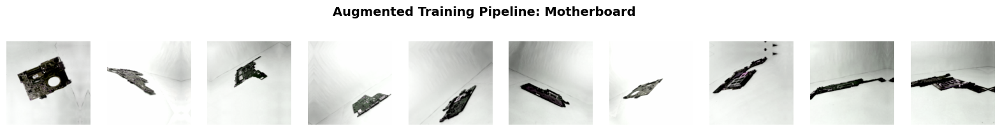

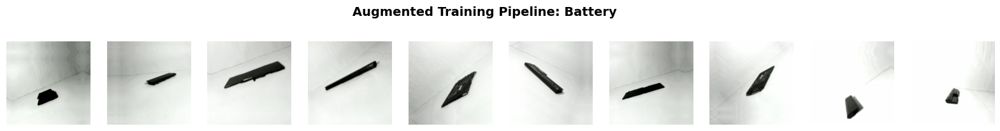

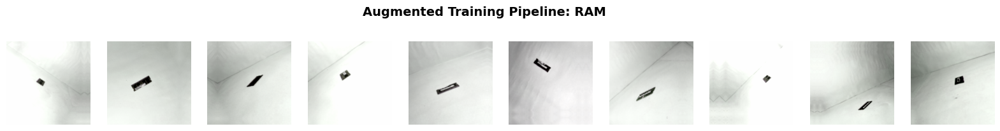

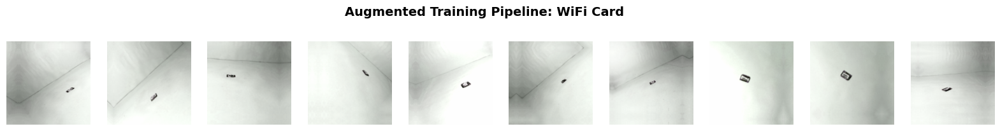

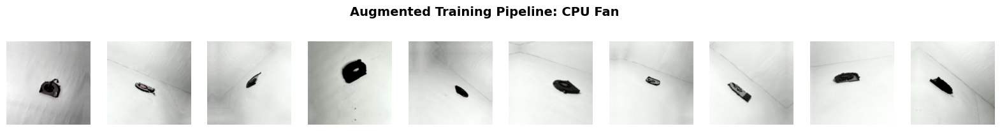

In [14]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


print("========================================")
print(" PRE-TRAINING DIAGNOSTICS & VERIFICATION ")
print("========================================")

print(f"Image Size: {IMAGE_SIZE}")
print(f"Batch Size: {BATCH_SIZE}")
print(
    f"Total Target Classes: "
    f"{len(TARGET_CLASSES)} ({TARGET_CLASSES})"
)

print("========================================\n")


# ==========================================================
# 1. CALCULATE EXACT IMAGE COUNTS DIRECTLY FROM THE FOLDERS
# ==========================================================

def count_images(split_name):

    split_dir = os.path.join(
        BASE_OUTPUT_DIR,
        split_name
    )

    if not os.path.exists(split_dir):
        return 0

    return sum(
        len(files)
        for root, dirs, files in os.walk(split_dir)
        if files
    )


train_count = count_images("train")
val_count = count_images("val")
test_count = count_images("test")

total_images = (
    train_count
    + val_count
    + test_count
)


print(f"Training Set:   {train_count} images")
print(f"Validation Set: {val_count} images")
print(f"Testing Set:    {test_count} images")
print(
    f"Total Unique Images in Pipeline: "
    f"{total_images}"
)


print("\n[NOTE ON AUGMENTATION SIZES]")

print(
    "Because Keras Data Augmentation runs "
    "'on-the-fly' during training, it does "
    "not save physical files."
)

print(
    "Instead, every epoch generates a uniquely "
    "mutated version of the training images."
)

print(
    f"Over a 50-epoch training run, "
    f"your model will see approximately "
    f"{train_count * 50} training image "
    f"presentations!"
)

print()


# ==========================================================
# 2. VISUALIZE THE AUGMENTED TRAINING DATA
# ==========================================================

print(
    "Generating visual preview of "
    "aggressively augmented training data..."
)

print(
    "If the colors look completely wrong "
    "(e.g., purple motherboards) or black-and-white, "
    "THE AUGMENTATION IS WORKING!\n"
)


# Create a dictionary to hold up to 10 images
# for each class
class_samples = {
    c: []
    for c in range(len(TARGET_CLASSES))
}

classes_filled = 0


# ==========================================================
# 3. COLLECT AUGMENTED SAMPLES
# ==========================================================

# Pull batches from the training set until we have
# 10 examples of each class
for images, labels in train_ds.unbatch().batch(64).take(20):

    # Apply augmentation manually so we can visualize
    # what the model will see
    aug_images = data_augmentation(
        images,
        training=True
    )

    # Convert one-hot labels to class indices
    label_indices = np.argmax(
        labels.numpy(),
        axis=1
    )


    for i in range(len(images)):

        c = label_indices[i]

        if len(class_samples[c]) < 10:

            # Convert augmented image to NumPy
            img = aug_images[i].numpy()

            # Scale image values for matplotlib
            img_display = (
                img - np.min(img)
            ) / (
                np.max(img) - np.min(img)
                + 1e-5
            )

            class_samples[c].append(
                img_display
            )


            # Check if this class now has
            # 10 samples
            if len(class_samples[c]) == 10:
                classes_filled += 1


        # Stop once every class has 10 images
        if classes_filled == len(TARGET_CLASSES):
            break


    if classes_filled == len(TARGET_CLASSES):
        break


# ==========================================================
# 4. PLOT AUGMENTED SAMPLES
# ==========================================================

# Plot one row for each class
for c_idx, class_name in enumerate(TARGET_CLASSES):

    samples = class_samples[c_idx]

    if not samples:
        continue


    plt.figure(figsize=(20, 2))

    plt.suptitle(
        f"Augmented Training Pipeline: {class_name}",
        fontsize=14,
        fontweight="bold",
        y=1.1
    )


    for i in range(len(samples)):

        ax = plt.subplot(
            1,
            10,
            i + 1
        )

        plt.imshow(samples[i])
        plt.axis("off")


    plt.show()

Cell 1 — Baseline DenseNet-121

In [18]:
# =============================================================================
# --- 5A. Baseline DenseNet-121 ---
# =============================================================================

baseline_densenet_model, baseline_densenet_base = build_densenet_model(
    name="Baseline_DenseNet-121"
)

baseline_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_epoch_base_dense = get_last_completed_epoch(
    "Baseline_DenseNet-121"
)

if start_epoch_base_dense > 0:
    baseline_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_DenseNet-121_best.keras"
        )
    )

baseline_densenet_history = baseline_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_base_dense,
    callbacks=get_training_callbacks(
        "Baseline_DenseNet-121"
    )
)

Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.3952 - loss: 1.6191
Epoch 1: val_loss improved from None to 0.48385, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 165s 4s/step - accuracy: 0.5179 - loss: 1.2045 - val_accuracy: 0.7857 - val_loss: 0.4838
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8085 - loss: 0.5405
Epoch 2: val_loss improved from 0.48385 to 0.34953, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_DenseNet-121_best.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 130s 4s/step - accuracy: 0.8196 - loss: 0.4949 - val_accuracy: 0.8857 - val_loss: 0.3495
Epoch 3/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8287 - loss:

Cell 2 — Baseline MobileNet-V2

In [19]:
# =============================================================================
# --- 5B. Baseline MobileNet-V2 ---
# =============================================================================

baseline_mobilenet_model, baseline_mobilenet_base = build_mobilenet_model(
    name="Baseline_MobileNet-V2"
)

baseline_mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

start_epoch_base_mobile = get_last_completed_epoch(
    "Baseline_MobileNet-V2"
)

if start_epoch_base_mobile > 0:
    baseline_mobilenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_MobileNet-V2_best.keras"
        )
    )

baseline_mobilenet_history = baseline_mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_base_mobile,
    callbacks=get_training_callbacks(
        "Baseline_MobileNet-V2"
    )
)

/tmp/ipykernel_2167/2397678732.py:68: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.5178 - loss: 1.3232
Epoch 1: val_loss improved from None to 0.43364, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.6554 - loss: 0.9207 - val_accuracy: 0.8286 - val_loss: 0.4336
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 955ms/step - accuracy: 0.7906 - loss: 0.5544
Epoch 2: val_loss improved from 0.43364 to 0.34574, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Baseline_MobileNet-V2_best.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.8179 - loss: 0.4866 - val_accuracy: 0.8571 - val_loss: 0.3457
Epoch 3/50
35/35 ━━━━━━━━

Cell 3 — Optimized DenseNet-121

In [20]:
# =============================================================================
# --- 5C. Optimized DenseNet-121 ---
# --- Focal Loss + Progressive Unfreezing ---
# =============================================================================

opt_densenet_model, opt_densenet_base = build_densenet_model(
    name="Optimized_DenseNet-121"
)


# =============================================================================
# Stage A: 50 Epochs — Frozen Backbone
# =============================================================================

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_A = get_last_completed_epoch(
    "Optimized_DenseNet-121_StepA"
)

if start_epoch_A > 0:
    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepA_best.keras"
        )
    )

opt_densenet_history_A = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_A,
    callbacks=get_training_callbacks(
        "Optimized_DenseNet-121_StepA"
    )
)


# =============================================================================
# Stage B1: Epochs 1–17
# =============================================================================

step_b_callbacks = get_training_callbacks(
    "Optimized_DenseNet-121_StepB"
)

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_B1 = get_last_completed_epoch(
    "Optimized_DenseNet-121_StepB"
)

if start_epoch_B1 > 0:
    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepB_best.keras"
        )
    )

opt_densenet_history_B1 = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=17,
    initial_epoch=start_epoch_B1,
    callbacks=step_b_callbacks
)


# =============================================================================
# Stage B2: Epochs 18–34 — Unfreeze Block 4
# =============================================================================

opt_densenet_base.trainable = True

for layer in opt_densenet_base.layers:
    if not layer.name.startswith(
        ("conv5", "pool4")
    ):
        layer.trainable = False

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_B2 = max(
    17,
    get_last_completed_epoch(
        "Optimized_DenseNet-121_StepB"
    )
)

opt_densenet_history_B2 = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=34,
    initial_epoch=start_epoch_B2,
    callbacks=step_b_callbacks
)


# =============================================================================
# Stage B3: Epochs 35–50 — Unfreeze Block 3
# =============================================================================

for layer in opt_densenet_base.layers:
    if layer.name.startswith(
        ("conv4", "pool3", "conv5", "pool4")
    ):
        layer.trainable = True

opt_densenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=CategoricalFocalLoss(),
    metrics=["accuracy"]
)

start_epoch_B3 = max(
    34,
    get_last_completed_epoch(
        "Optimized_DenseNet-121_StepB"
    )
)

opt_densenet_history_B3 = opt_densenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    initial_epoch=start_epoch_B3,
    callbacks=step_b_callbacks
)

Epoch 1/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.4307 - loss: 0.2639
Epoch 1: val_loss improved from None to 0.01704, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_best.keras
35/35 ━━━━━━━━━━━━━━━━━━━━ 150s 4s/step - accuracy: 0.5875 - loss: 0.1667 - val_accuracy: 0.9429 - val_loss: 0.0170
Epoch 2/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7627 - loss: 0.0720
Epoch 2: val_loss did not improve from 0.01704
35/35 ━━━━━━━━━━━━━━━━━━━━ 123s 4s/step - accuracy: 0.8036 - loss: 0.0564 - val_accuracy: 0.9000 - val_loss: 0.0240
Epoch 3/50
35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8380 - loss: 0.0418
Epoch 3: val_loss improved from 0.01704 to 0.01071, saving model to /content/drive/MyDrive/Thesis/Model_Checkpoints/Optimized_DenseNet-121_StepA_best.keras

Epoch 3: finished saving model to /cont

# 6. Shared Evaluation & Statistical Testing
## This generates your final metrics table, confusion matrices, and runs the ANOVA/Kruskal-Wallis tests.

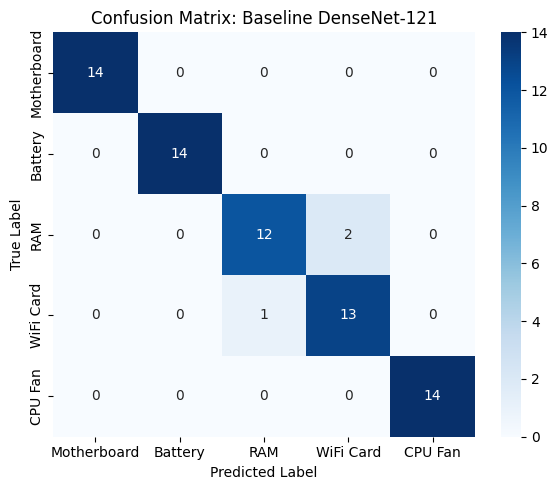

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 502 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


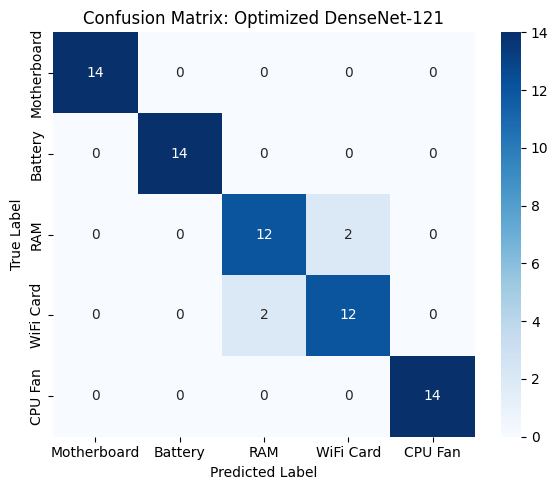

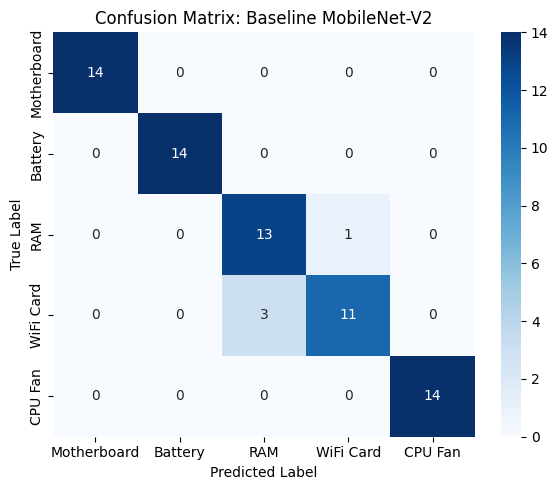

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,AUC-ROC (macro),Inference Time (ms),Model Size (MB),FLOPs
0,Baseline DenseNet-121,0.957143,0.957949,0.957143,0.957088,0.996939,869.472809,31.330778,0
1,Optimized DenseNet-121,0.942857,0.942857,0.942857,0.942857,0.996939,893.793519,31.330925,0
2,Baseline MobileNet-V2,0.942857,0.945833,0.942857,0.942564,0.997959,275.435209,12.963179,0


--- Shapiro-Wilk Normality Test ---
Base Dense: W=0.9794, p=0.8082 | Opt Dense: W=0.9638, p=0.3854 | Base Mobile: W=0.9237, p=0.0334

Distributions NOT all normal. Proceeding with Kruskal-Wallis.
Kruskal-Wallis H-stat=3.4572, p-value=1.7753e-01


In [21]:
def calculate_flops_fallback(model):
    if get_flops:
        try: return get_flops(model, batch_size=1)
        except Exception: pass
    return 0

def evaluate_model(model, name, test_ds, checkpoint_path):
    if os.path.exists(checkpoint_path): model.load_weights(checkpoint_path)

    test_labels = np.concatenate([y for x, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)
    predictions = model.predict(test_ds, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)

    rep = classification_report(true_classes, predicted_classes, target_names=TARGET_CLASSES, output_dict=True)

    # Inference Time
    sample_image = next(iter(test_ds))[0][0:1]
    for _ in range(10): model(sample_image, training=False)
    start_time = time.time()
    for _ in range(100): model(sample_image, training=False)
    mean_inference_time_ms = ((time.time() - start_time) / 100) * 1000

    # Confusion Matrix
    cm = confusion_matrix(true_classes, predicted_classes)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=TARGET_CLASSES, yticklabels=TARGET_CLASSES)
    plt.title(f'Confusion Matrix: {name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.tight_layout()
    plt.savefig(f'cm_{name.replace(" ", "_")}.png')
    plt.show()

    return {
        "Model": name,
        "Accuracy": accuracy_score(true_classes, predicted_classes),
        "Macro Precision": rep['macro avg']['precision'],
        "Macro Recall": rep['macro avg']['recall'],
        "Macro F1": rep['macro avg']['f1-score'],
        "AUC-ROC (macro)": roc_auc_score(test_labels, predictions, multi_class='ovr', average='macro'),
        "Inference Time (ms)": mean_inference_time_ms,
        "Model Size (MB)": os.path.getsize(checkpoint_path) / (1024 * 1024) if os.path.exists(checkpoint_path) else 0,
        "FLOPs": calculate_flops_fallback(model)
    }

# Run Evaluations
results = [
    evaluate_model(baseline_densenet_model, "Baseline DenseNet-121", test_ds, os.path.join(CHECKPOINT_DIR, "Baseline_DenseNet-121_best.keras")),
    evaluate_model(opt_densenet_model, "Optimized DenseNet-121", test_ds, os.path.join(CHECKPOINT_DIR, "Optimized_DenseNet-121_StepB_best.keras")),
    evaluate_model(baseline_mobilenet_model, "Baseline MobileNet-V2", test_ds, os.path.join(CHECKPOINT_DIR, "Baseline_MobileNet-V2_best.keras"))
]
display(pd.DataFrame(results))

# Statistical Testing
def paired_bootstrap_f1(models_dict, test_ds, n_iterations=30):
    test_labels = np.concatenate([y for x, y in test_ds], axis=0)
    true_classes = np.argmax(test_labels, axis=1)
    preds = {name: np.argmax(model.predict(test_ds, verbose=0), axis=1) for name, model in models_dict.items()}
    f1_scores = {name: [] for name in models_dict.keys()}
    np.random.seed(42)

    for _ in range(n_iterations):
        indices = np.random.choice(len(true_classes), len(true_classes), replace=True)
        sample_true = true_classes[indices]
        for name in models_dict.keys():
            rep = classification_report(sample_true, preds[name][indices], output_dict=True, zero_division=0)
            f1_scores[name].append(rep['macro avg']['f1-score'])
    return f1_scores

f1_results = paired_bootstrap_f1({'Base_Dense': baseline_densenet_model, 'Opt_Dense': opt_densenet_model, 'Base_Mobile': baseline_mobilenet_model}, test_ds)
f1_base_dense, f1_opt_dense, f1_base_mobile = np.array(f1_results['Base_Dense']), np.array(f1_results['Opt_Dense']), np.array(f1_results['Base_Mobile'])

print("--- Shapiro-Wilk Normality Test ---")
stat1, p1 = shapiro(f1_base_dense)
stat2, p2 = shapiro(f1_opt_dense)
stat3, p3 = shapiro(f1_base_mobile)
print(f"Base Dense: W={stat1:.4f}, p={p1:.4f} | Opt Dense: W={stat2:.4f}, p={p2:.4f} | Base Mobile: W={stat3:.4f}, p={p3:.4f}")

if (p1 > 0.05) and (p2 > 0.05) and (p3 > 0.05):
    print("\nDistributions normal. Proceeding with one-way ANOVA.")
    stat, p_val = f_oneway(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"ANOVA F-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        data = np.concatenate([f1_base_dense, f1_opt_dense, f1_base_mobile])
        labels = ['Base_Dense']*30 + ['Opt_Dense']*30 + ['Base_Mobile']*30
        print(pairwise_tukeyhsd(endog=data, groups=labels, alpha=0.05))
else:
    print("\nDistributions NOT all normal. Proceeding with Kruskal-Wallis.")
    stat, p_val = kruskal(f1_base_dense, f1_opt_dense, f1_base_mobile)
    print(f"Kruskal-Wallis H-stat={stat:.4f}, p-value={p_val:.4e}")
    if p_val < 0.05:
        print(sp.posthoc_dunn([f1_base_dense, f1_opt_dense, f1_base_mobile], p_adjust='bonferroni'))

Models not found in memory. Building and loading from checkpoints...
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/tmp/ipykernel_4103/2397678732.py:68: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights="imagenet", include_top=False, input_tensor=x)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Models loaded successfully!

Upload ONE or MULTIPLE images (Press Ctrl+A / Cmd+A to select a whole folder):


Saving wificard_4.avif to wificard_4 (1).avif
Saving wificard_5.jpg to wificard_5.jpg
Saving wificard_3.jpg to wificard_3.jpg
Saving wificard_2.webp to wificard_2.webp
Saving wificard_1.jpg to wificard_1.jpg
Saving ram_1.jpg to ram_1.jpg
Saving ram_2.jpg to ram_2.jpg
Saving ram_4.jpg to ram_4.jpg
Saving ram_5.webp to ram_5.webp
Saving ram3.jpg to ram3.jpg
Saving motherboard_5.jpg to motherboard_5.jpg
Saving motherboard_3.jpeg to motherboard_3.jpeg
Saving motherboard_1 to motherboard_1
Saving fan_5.jpeg to fan_5.jpeg
Saving fan_4.jpg to fan_4.jpg
Saving fan_3.webp to fan_3.webp
Saving fan_2.jpg to fan_2.jpg
Saving fan_1.jpg to fan_1.jpg
Saving battery_4.jpg to battery_4.jpg
Saving battery_3.webp to battery_3.webp
Saving battery_2.jpg to battery_2.jpg
Saving battery_1.jpg to battery_1.jpg


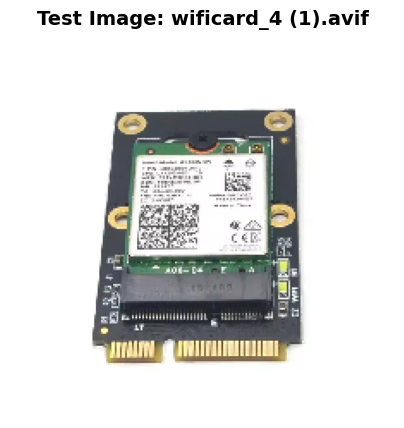

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.88% confidence)
 [2] Optimized DenseNet-121 : Battery      (63.11% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (96.99% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.88% | Opt Dense:  36.47% | MobileNet:  96.99%
 Battery      | Base Dense:   0.12% | Opt Dense:  63.11% | MobileNet:   2.69%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.27% | MobileNet:   0.07%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.12%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.15% | MobileNet:   0.12%



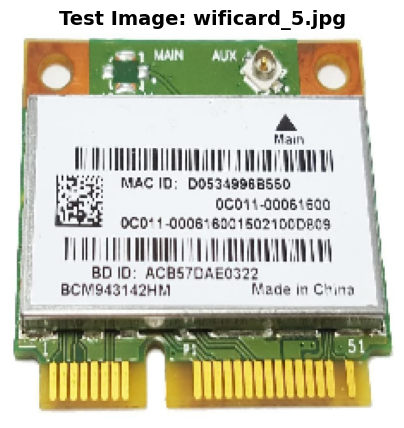

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.99% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (81.84% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (49.60% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.99% | Opt Dense:  81.84% | MobileNet:  49.60%
 Battery      | Base Dense:   0.01% | Opt Dense:   9.44% | MobileNet:  48.68%
 RAM          | Base Dense:   0.00% | Opt Dense:   7.67% | MobileNet:   1.01%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.26% | MobileNet:   0.10%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.79% | MobileNet:   0.61%



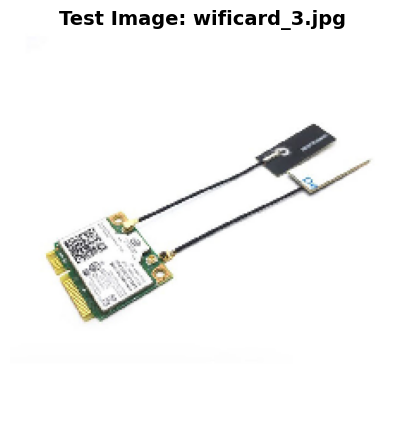

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.01% confidence)
 [2] Optimized DenseNet-121 : Battery      (63.50% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.30% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.01% | Opt Dense:  32.53% | MobileNet:  99.30%
 Battery      | Base Dense:   0.96% | Opt Dense:  63.50% | MobileNet:   0.64%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.20% | MobileNet:   0.01%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.06% | MobileNet:   0.02%
 CPU Fan      | Base Dense:   0.03% | Opt Dense:   3.70% | MobileNet:   0.03%



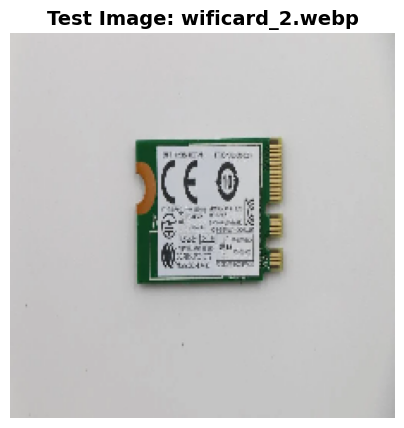

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : RAM          (36.02% confidence)
 [2] Optimized DenseNet-121 : RAM          (31.15% confidence)
 [3] Baseline MobileNet-V2  : Battery      (33.41% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  34.10% | Opt Dense:   2.09% | MobileNet:  22.21%
 Battery      | Base Dense:  11.13% | Opt Dense:  24.39% | MobileNet:  33.41%
 RAM          | Base Dense:  36.02% | Opt Dense:  31.15% | MobileNet:  20.02%
 WiFi Card    | Base Dense:   0.77% | Opt Dense:  17.16% | MobileNet:   5.17%
 CPU Fan      | Base Dense:  17.97% | Opt Dense:  25.21% | MobileNet:  19.18%



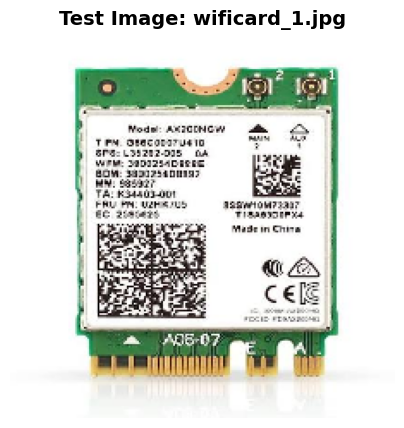

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.85% confidence)
 [2] Optimized DenseNet-121 : Battery      (47.34% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (85.29% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.85% | Opt Dense:  40.37% | MobileNet:  85.29%
 Battery      | Base Dense:   0.11% | Opt Dense:  47.34% | MobileNet:  12.94%
 RAM          | Base Dense:   0.04% | Opt Dense:   9.24% | MobileNet:   0.54%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   1.10% | MobileNet:   0.06%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   1.95% | MobileNet:   1.18%



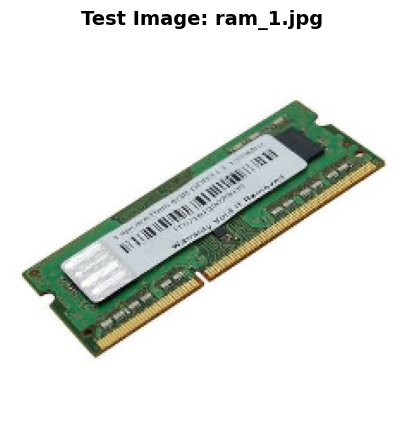

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (92.36% confidence)
 [2] Optimized DenseNet-121 : Battery      (85.43% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (91.20% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  92.36% | Opt Dense:  14.33% | MobileNet:  91.20%
 Battery      | Base Dense:   7.63% | Opt Dense:  85.43% | MobileNet:   6.51%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.08% | MobileNet:   2.04%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.22%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.15% | MobileNet:   0.02%



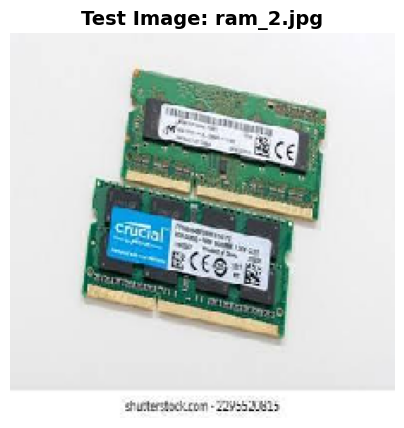

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.95% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (98.54% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (88.77% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.95% | Opt Dense:  98.54% | MobileNet:  88.77%
 Battery      | Base Dense:   0.00% | Opt Dense:   1.12% | MobileNet:  10.72%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.15% | MobileNet:   0.38%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.04%
 CPU Fan      | Base Dense:   0.05% | Opt Dense:   0.19% | MobileNet:   0.10%



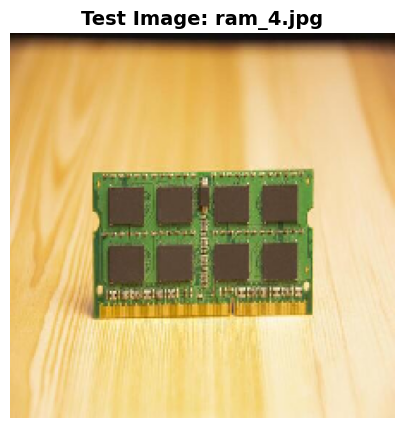

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (95.63% confidence)
 [2] Optimized DenseNet-121 : Battery      (69.36% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (88.07% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  95.63% | Opt Dense:  30.46% | MobileNet:  88.07%
 Battery      | Base Dense:   4.36% | Opt Dense:  69.36% | MobileNet:  11.85%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.10% | MobileNet:   0.02%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.01%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.05% | MobileNet:   0.04%



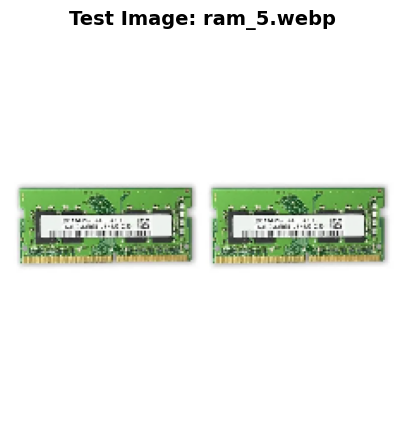

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (88.34% confidence)
 [2] Optimized DenseNet-121 : RAM          (41.13% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (84.56% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  88.34% | Opt Dense:  10.74% | MobileNet:  84.56%
 Battery      | Base Dense:   1.88% | Opt Dense:  21.57% | MobileNet:   8.02%
 RAM          | Base Dense:   6.39% | Opt Dense:  41.13% | MobileNet:   7.07%
 WiFi Card    | Base Dense:   0.95% | Opt Dense:  14.33% | MobileNet:   0.32%
 CPU Fan      | Base Dense:   2.44% | Opt Dense:  12.24% | MobileNet:   0.03%



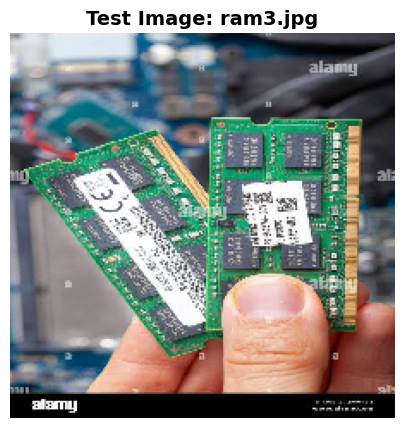

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (94.41% confidence)
 [2] Optimized DenseNet-121 : RAM          (58.43% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (94.15% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  94.41% | Opt Dense:   7.44% | MobileNet:  94.15%
 Battery      | Base Dense:   1.72% | Opt Dense:  27.70% | MobileNet:   5.78%
 RAM          | Base Dense:   3.72% | Opt Dense:  58.43% | MobileNet:   0.03%
 WiFi Card    | Base Dense:   0.13% | Opt Dense:   6.35% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.08% | MobileNet:   0.03%



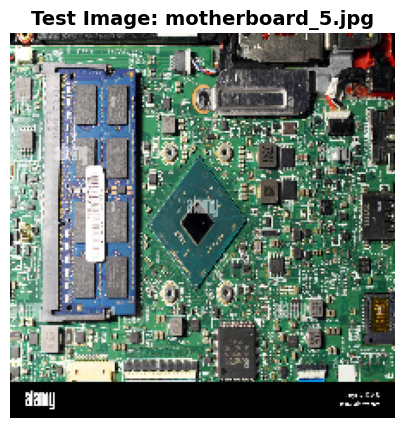

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.98% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (97.12% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (96.26% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.98% | Opt Dense:  97.12% | MobileNet:  96.26%
 Battery      | Base Dense:   0.01% | Opt Dense:   2.34% | MobileNet:   2.54%
 RAM          | Base Dense:   0.01% | Opt Dense:   0.36% | MobileNet:   0.58%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.04% | MobileNet:   0.35%
 CPU Fan      | Base Dense:   0.01% | Opt Dense:   0.14% | MobileNet:   0.27%



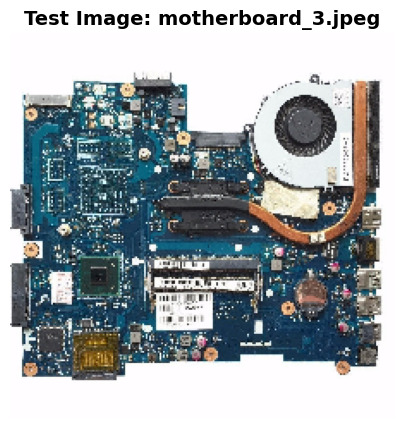

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.77% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.91% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.77% | MobileNet:  99.91%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.09% | MobileNet:   0.07%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.13% | MobileNet:   0.01%



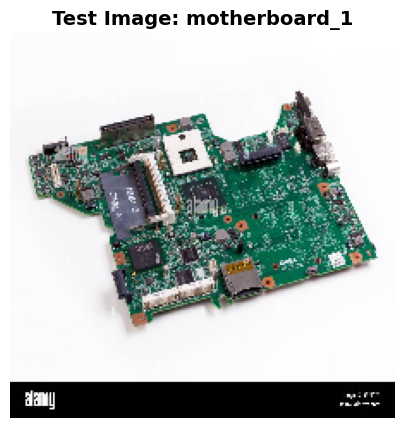

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (100.00% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (99.93% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (99.96% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense: 100.00% | Opt Dense:  99.93% | MobileNet:  99.96%
 Battery      | Base Dense:   0.00% | Opt Dense:   0.05% | MobileNet:   0.04%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.00%



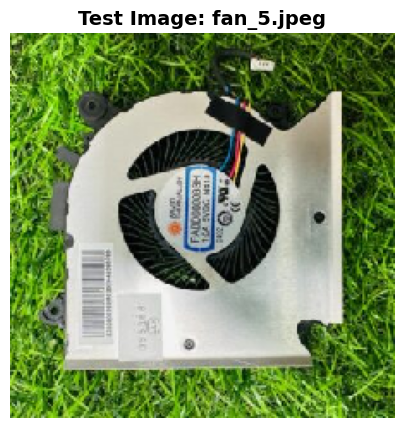

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : CPU Fan      (76.03% confidence)
 [2] Optimized DenseNet-121 : Battery      (55.18% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (94.90% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  23.04% | Opt Dense:  15.83% | MobileNet:  94.90%
 Battery      | Base Dense:   0.93% | Opt Dense:  55.18% | MobileNet:   4.56%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.03%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 CPU Fan      | Base Dense:  76.03% | Opt Dense:  28.98% | MobileNet:   0.50%



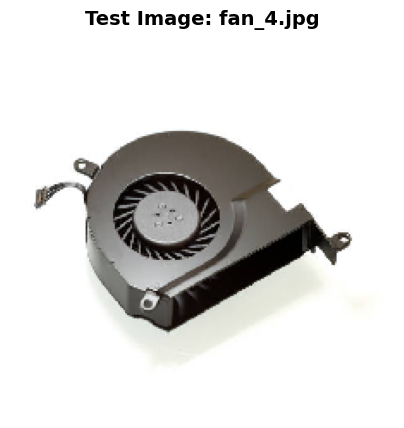

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : CPU Fan      (96.44% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (52.06% confidence)
 [3] Baseline MobileNet-V2  : CPU Fan      (65.20% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   2.08% | Opt Dense:   5.26% | MobileNet:  28.65%
 Battery      | Base Dense:   1.48% | Opt Dense:  42.67% | MobileNet:   5.50%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.46%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.19%
 CPU Fan      | Base Dense:  96.44% | Opt Dense:  52.06% | MobileNet:  65.20%



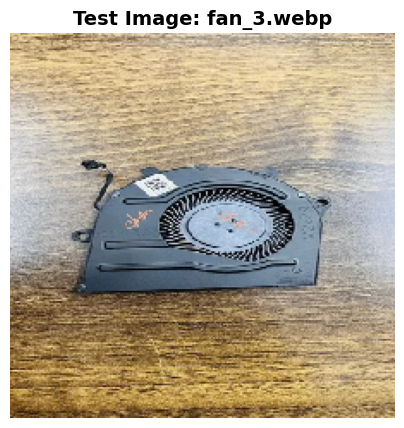

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : CPU Fan      (79.29% confidence)
 [2] Optimized DenseNet-121 : CPU Fan      (69.71% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (78.44% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  20.50% | Opt Dense:  25.08% | MobileNet:  78.44%
 Battery      | Base Dense:   0.21% | Opt Dense:   5.15% | MobileNet:  13.78%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.04% | MobileNet:   0.43%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.02% | MobileNet:   0.97%
 CPU Fan      | Base Dense:  79.29% | Opt Dense:  69.71% | MobileNet:   6.39%



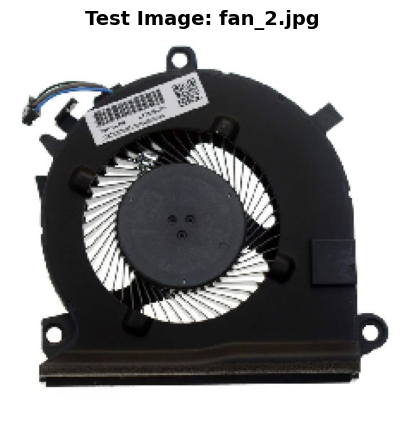

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (96.91% confidence)
 [2] Optimized DenseNet-121 : Battery      (56.33% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (65.27% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  96.91% | Opt Dense:  33.35% | MobileNet:  65.27%
 Battery      | Base Dense:   1.03% | Opt Dense:  56.33% | MobileNet:  13.12%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   4.82%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   5.50%
 CPU Fan      | Base Dense:   2.06% | Opt Dense:  10.25% | MobileNet:  11.28%



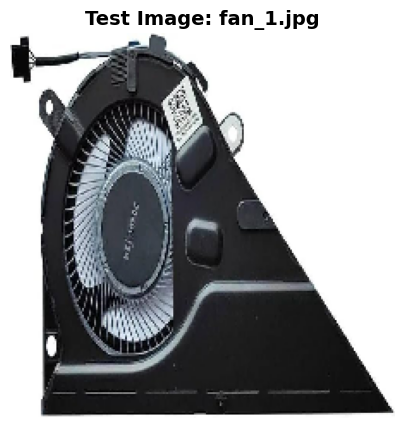

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : CPU Fan      (59.55% confidence)
 [2] Optimized DenseNet-121 : Battery      (69.02% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (85.03% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  37.10% | Opt Dense:  17.88% | MobileNet:  85.03%
 Battery      | Base Dense:   3.35% | Opt Dense:  69.02% | MobileNet:   2.64%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   1.89%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   5.64%
 CPU Fan      | Base Dense:  59.55% | Opt Dense:  13.09% | MobileNet:   4.81%



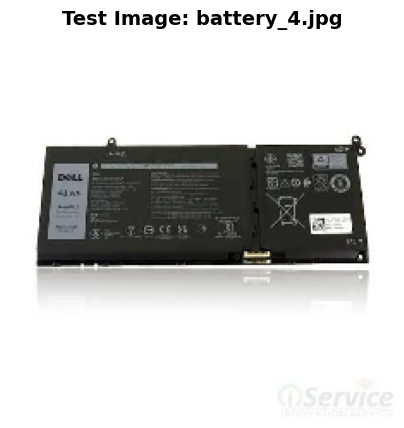

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (96.68% confidence)
 [2] Optimized DenseNet-121 : Battery      (63.31% confidence)
 [3] Baseline MobileNet-V2  : Battery      (87.73% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  96.68% | Opt Dense:  35.34% | MobileNet:  11.91%
 Battery      | Base Dense:   3.03% | Opt Dense:  63.31% | MobileNet:  87.73%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.03% | MobileNet:   0.10%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 CPU Fan      | Base Dense:   0.28% | Opt Dense:   1.32% | MobileNet:   0.25%



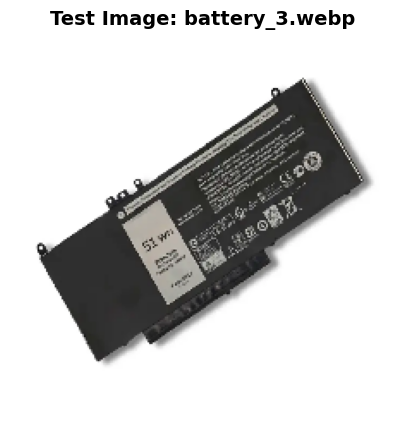

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (65.30% confidence)
 [2] Optimized DenseNet-121 : Battery      (96.01% confidence)
 [3] Baseline MobileNet-V2  : Battery      (65.68% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  65.30% | Opt Dense:   3.93% | MobileNet:  34.23%
 Battery      | Base Dense:  34.68% | Opt Dense:  96.01% | MobileNet:  65.68%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.06%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.01%
 CPU Fan      | Base Dense:   0.02% | Opt Dense:   0.05% | MobileNet:   0.03%



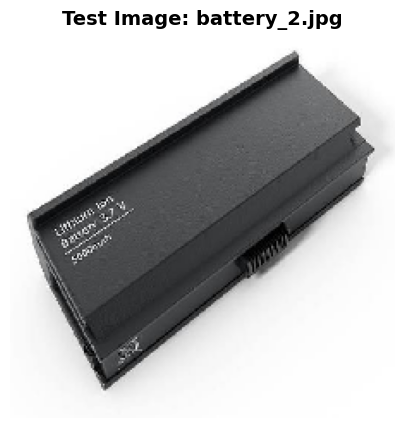

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Battery      (100.00% confidence)
 [2] Optimized DenseNet-121 : Battery      (99.87% confidence)
 [3] Baseline MobileNet-V2  : Battery      (99.08% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:   0.00% | Opt Dense:   0.04% | MobileNet:   0.78%
 Battery      | Base Dense: 100.00% | Opt Dense:  99.87% | MobileNet:  99.08%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.01%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.00% | MobileNet:   0.00%
 CPU Fan      | Base Dense:   0.00% | Opt Dense:   0.07% | MobileNet:   0.12%



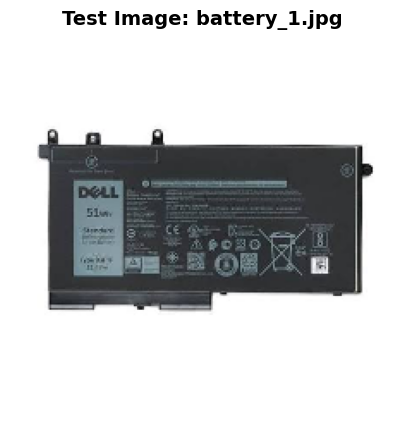

                    MODEL PREDICTION COMPARISON
 [1] Baseline DenseNet-121  : Motherboard  (99.06% confidence)
 [2] Optimized DenseNet-121 : Motherboard  (79.68% confidence)
 [3] Baseline MobileNet-V2  : Motherboard  (80.50% confidence)

--- Detailed Probabilities Breakdown ---
 Motherboard  | Base Dense:  99.06% | Opt Dense:  79.68% | MobileNet:  80.50%
 Battery      | Base Dense:   0.58% | Opt Dense:  17.01% | MobileNet:  18.22%
 RAM          | Base Dense:   0.00% | Opt Dense:   0.09% | MobileNet:   0.33%
 WiFi Card    | Base Dense:   0.00% | Opt Dense:   0.01% | MobileNet:   0.12%
 CPU Fan      | Base Dense:   0.37% | Opt Dense:   3.21% | MobileNet:   0.83%



In [12]:
import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.pyplot as plt


# ====================================================================
# SAFETY CHECK: LOAD MODELS IF NOT ALREADY IN MEMORY
# ====================================================================

if "baseline_densenet_model" not in globals():
    print(
        "Models not found in memory. "
        "Building and loading from checkpoints..."
    )

    # Build the architectures
    baseline_densenet_model, _ = build_densenet_model(
        name="Baseline_DenseNet-121"
    )

    opt_densenet_model, _ = build_densenet_model(
        name="Optimized_DenseNet-121"
    )

    baseline_mobilenet_model, _ = build_mobilenet_model(
        name="Baseline_MobileNet-V2"
    )

    # Load the saved .keras weights
    baseline_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_DenseNet-121_best.keras"
        )
    )

    opt_densenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Optimized_DenseNet-121_StepB_best.keras"
        )
    )

    baseline_mobilenet_model.load_weights(
        os.path.join(
            CHECKPOINT_DIR,
            "Baseline_MobileNet-V2_best.keras"
        )
    )

    print(
        "Models loaded successfully!\n"
    )


# ====================================================================


print(
    "Upload ONE or MULTIPLE images "
    "(Press Ctrl+A / Cmd+A to select a whole folder):"
)

uploaded = files.upload()

for filename in uploaded.keys():

    # 1. Load and resize the uploaded image
    img_path = filename

    img = image.load_img(
        img_path,
        target_size=IMAGE_SIZE
    )

    img_array = image.img_to_array(img)

    img_batch = np.expand_dims(
        img_array,
        axis=0
    )

    # 2. Get predictions from all three models
    preds_base_dense = (
        baseline_densenet_model
        .predict(img_batch, verbose=0)[0]
    )

    preds_opt_dense = (
        opt_densenet_model
        .predict(img_batch, verbose=0)[0]
    )

    preds_mobile = (
        baseline_mobilenet_model
        .predict(img_batch, verbose=0)[0]
    )

    # 3. Helper function to find the winning class and confidence
    def get_top_pred(preds):
        idx = np.argmax(preds)

        return (
            TARGET_CLASSES[idx],
            preds[idx] * 100
        )

    class_base_dense, conf_base_dense = (
        get_top_pred(preds_base_dense)
    )

    class_opt_dense, conf_opt_dense = (
        get_top_pred(preds_opt_dense)
    )

    class_mobile, conf_mobile = (
        get_top_pred(preds_mobile)
    )

    # 4. Display the uploaded image
    plt.figure(figsize=(5, 5))

    plt.imshow(img)
    plt.axis("off")

    plt.title(
        f"Test Image: {filename}",
        fontsize=14,
        fontweight="bold"
    )

    plt.show()

    # 5. Print out the comparative results
    print(
        "===================================================================="
    )

    print(
        "                    MODEL PREDICTION COMPARISON"
    )

    print(
        "===================================================================="
    )

    print(
        f" [1] Baseline DenseNet-121  : "
        f"{class_base_dense:12s} "
        f"({conf_base_dense:.2f}% confidence)"
    )

    print(
        f" [2] Optimized DenseNet-121 : "
        f"{class_opt_dense:12s} "
        f"({conf_opt_dense:.2f}% confidence)"
    )

    print(
        f" [3] Baseline MobileNet-V2  : "
        f"{class_mobile:12s} "
        f"({conf_mobile:.2f}% confidence)"
    )

    print(
        "===================================================================="
    )

    print(
        "\n--- Detailed Probabilities Breakdown ---"
    )

    for i, c in enumerate(TARGET_CLASSES):
        print(
            f" {c:12s} | "
            f"Base Dense: {preds_base_dense[i] * 100:6.2f}% | "
            f"Opt Dense: {preds_opt_dense[i] * 100:6.2f}% | "
            f"MobileNet: {preds_mobile[i] * 100:6.2f}%"
        )

    print(
        "====================================================================\n"
    )

In [13]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

print(
    "Upload ONE or MULTIPLE images to generate the PDF Report:"
)

uploaded = files.upload()

pdf_filename = "OOD_Model_Evaluation_Report.pdf"

print(
    f"\nGenerating {pdf_filename}..."
)

# Open a PDF file to save our pages into
with PdfPages(pdf_filename) as pdf:

    for filename in uploaded.keys():

        # 1. Load and process image
        img_path = filename

        img = image.load_img(
            img_path,
            target_size=IMAGE_SIZE
        )

        img_array = image.img_to_array(img)

        img_batch = np.expand_dims(
            img_array,
            axis=0
        )

        # 2. Get predictions
        preds_base_dense = (
            baseline_densenet_model
            .predict(img_batch, verbose=0)[0]
        )

        preds_opt_dense = (
            opt_densenet_model
            .predict(img_batch, verbose=0)[0]
        )

        preds_mobile = (
            baseline_mobilenet_model
            .predict(img_batch, verbose=0)[0]
        )

        def get_top_pred(preds):
            idx = np.argmax(preds)

            return (
                TARGET_CLASSES[idx],
                preds[idx] * 100
            )

        class_base_dense, conf_base_dense = (
            get_top_pred(preds_base_dense)
        )

        class_opt_dense, conf_opt_dense = (
            get_top_pred(preds_opt_dense)
        )

        class_mobile, conf_mobile = (
            get_top_pred(preds_mobile)
        )

        # 3. Create a landscape page
        fig = plt.figure(figsize=(12, 6))

        # --- LEFT SIDE: The Image ---
        ax1 = plt.subplot(1, 2, 1)

        ax1.imshow(img)
        ax1.axis("off")

        ax1.set_title(
            f"Test Subject: {filename}",
            fontsize=14,
            fontweight="bold"
        )

        # --- RIGHT SIDE: The Data Report ---
        ax2 = plt.subplot(1, 2, 2)
        ax2.axis("off")

        # Format the text report using a monospace font
        # so the columns align perfectly
        report_text = (
            "MODEL PREDICTION COMPARISON\n"
        )

        report_text += (
            f"{'=' * 40}\n"
        )

        report_text += (
            f"[1] Base DenseNet-121: "
            f"{class_base_dense} "
            f"({conf_base_dense:.1f}%)\n"
        )

        report_text += (
            f"[2] Opt DenseNet-121 : "
            f"{class_opt_dense} "
            f"({conf_opt_dense:.1f}%)\n"
        )

        report_text += (
            f"[3] Base MobileNet-V2: "
            f"{class_mobile} "
            f"({conf_mobile:.1f}%)\n\n\n"
        )

        report_text += (
            "DETAILED PROBABILITIES BREAKDOWN\n"
        )

        report_text += (
            f"{'=' * 70}\n"
        )

        report_text += (
            f"{'Class':<14s} | "
            f"{'Base Dense':<12s} | "
            f"{'Opt Dense':<12s} | "
            f"{'MobileNet':<12s}\n"
        )

        report_text += (
            f"{'-' * 70}\n"
        )

        for i, c in enumerate(TARGET_CLASSES):
            report_text += (
                f"{c:<14s} | "
                f"{preds_base_dense[i] * 100:>9.2f}% | "
                f"{preds_opt_dense[i] * 100:>9.2f}% | "
                f"{preds_mobile[i] * 100:>9.2f}%\n"
            )

        # Draw the text onto the right side of the PDF page
        ax2.text(
            0.0,
            0.8,
            report_text,
            fontsize=11,
            family="monospace",
            verticalalignment="top"
        )

        plt.tight_layout()

        # Save this figure as a new page in the PDF
        pdf.savefig(fig)
        plt.close()

print(
    f"Successfully created {pdf_filename}!"
)

# Automatically trigger the browser download
files.download(pdf_filename)

Upload ONE or MULTIPLE images to generate the PDF Report:



Generating OOD_Model_Evaluation_Report.pdf...
Successfully created OOD_Model_Evaluation_Report.pdf!


FileNotFoundError: Cannot find file: OOD_Model_Evaluation_Report.pdf

Upload an image to generate an AI Attention Heatmap:


Saving wificard_5.jpg to wificard_5 (3).jpg
Saving wificard_4.avif to wificard_4 (3).avif
Saving wificard_3.jpg to wificard_3 (3).jpg
Saving wificard_2.webp to wificard_2 (3).webp
Saving wificard_1.jpg to wificard_1 (3).jpg
Saving ram3.jpg to ram3 (3).jpg
Saving ram_5.webp to ram_5 (3).webp
Saving ram_4.jpg to ram_4 (3).jpg
Saving ram_2.jpg to ram_2 (3).jpg
Saving ram_1.jpg to ram_1 (3).jpg
Saving motherboard_5.jpg to motherboard_5 (3).jpg
Saving motherboard_4.png to motherboard_4 (3).png
Saving motherboard_3.jpeg to motherboard_3 (3).jpeg
Saving motherboard_2.webp to motherboard_2 (3).webp
Saving motherboard_1 to motherboard_1 (3)
Saving fan_5.jpeg to fan_5 (3).jpeg
Saving fan_4.jpg to fan_4 (3).jpg
Saving fan_3.webp to fan_3 (3).webp
Saving fan_2.jpg to fan_2 (3).jpg
Saving fan_1.jpg to fan_1 (3).jpg
Saving battery_5.jpg to battery_5 (3).jpg
Saving battery_4.jpg to battery_4 (3).jpg
Saving battery_3.webp to battery_3 (3).webp
Saving battery_2.jpg to battery_2 (3).jpg
Saving battery_1

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_1053']]
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/tmp/ipykernel_2167/3911238287.py:119: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")


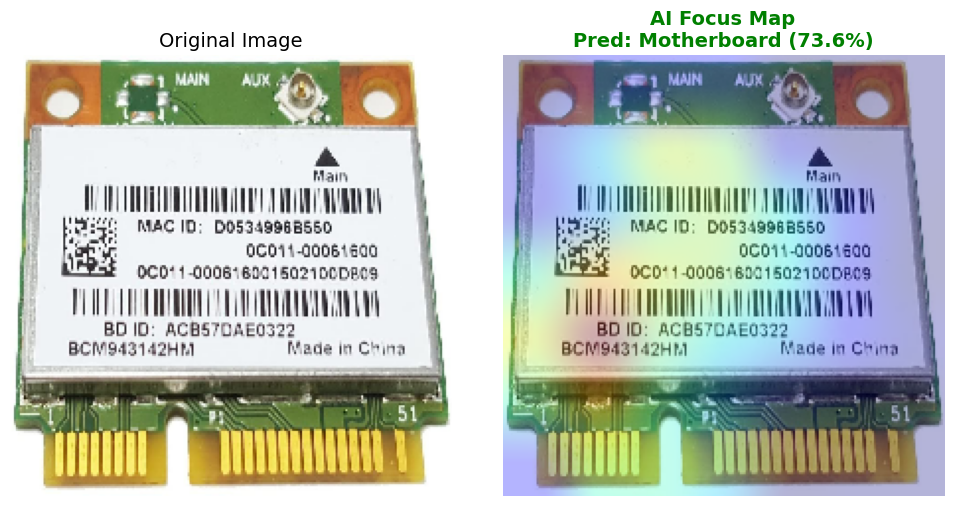

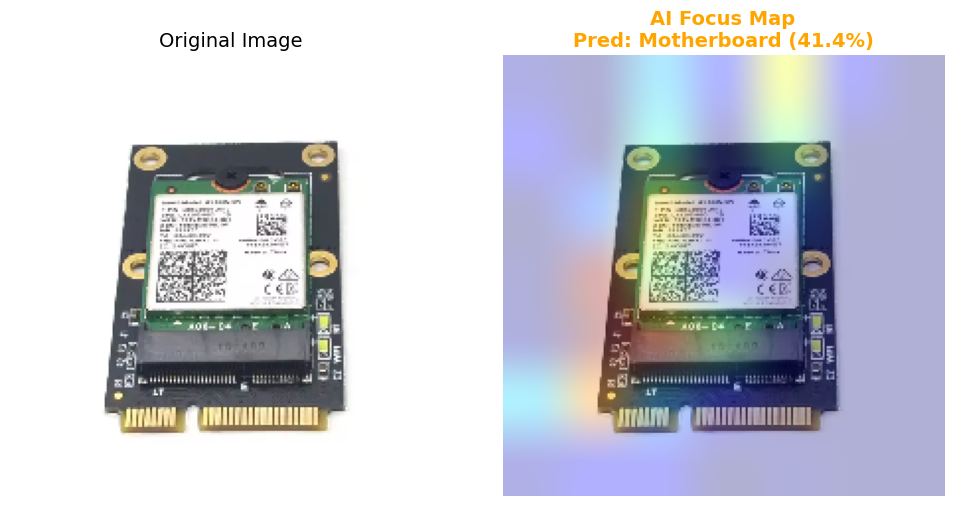

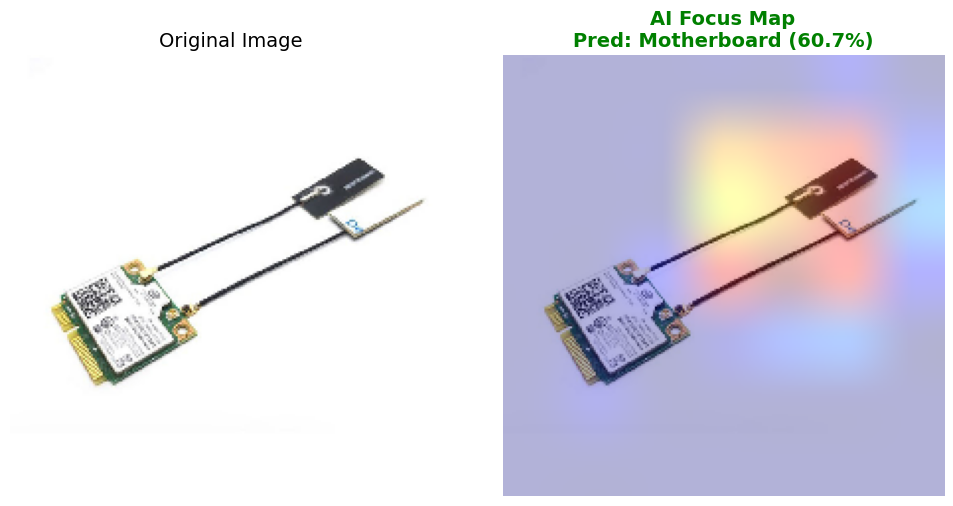

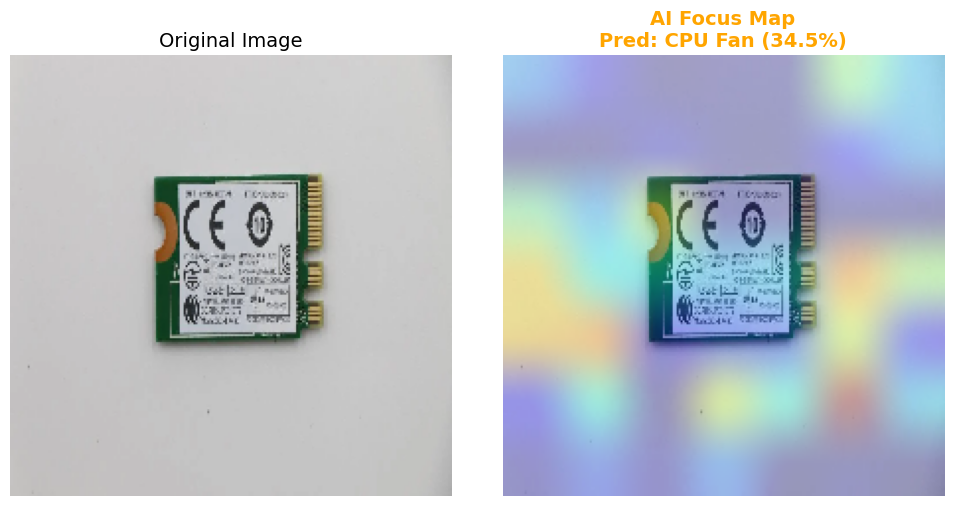

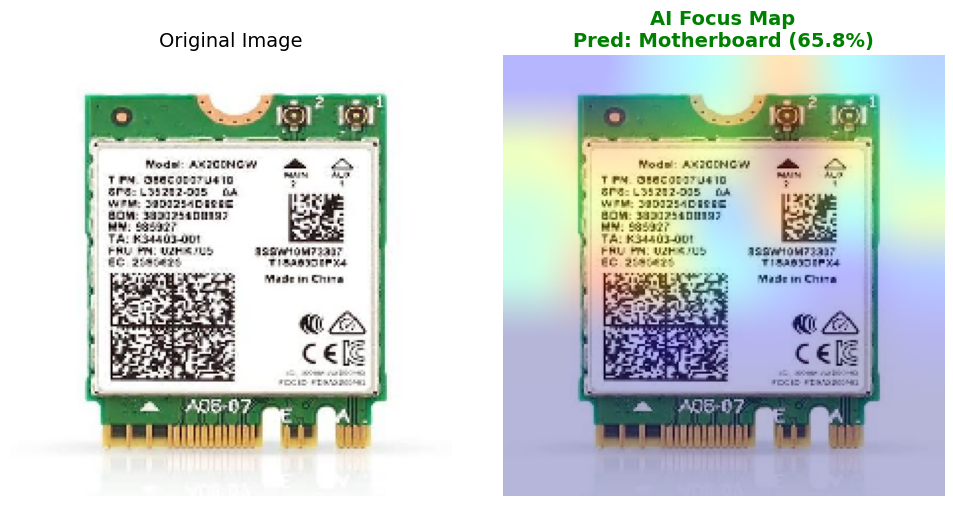

...

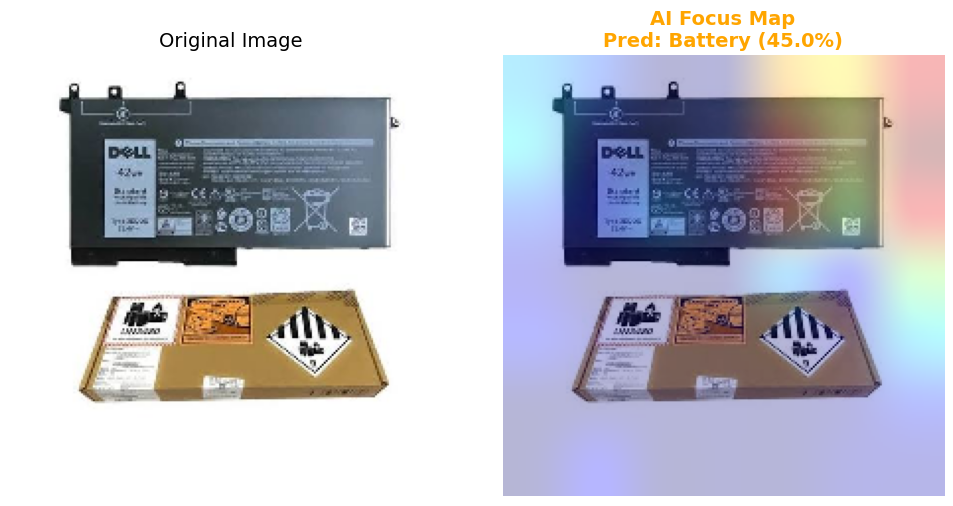

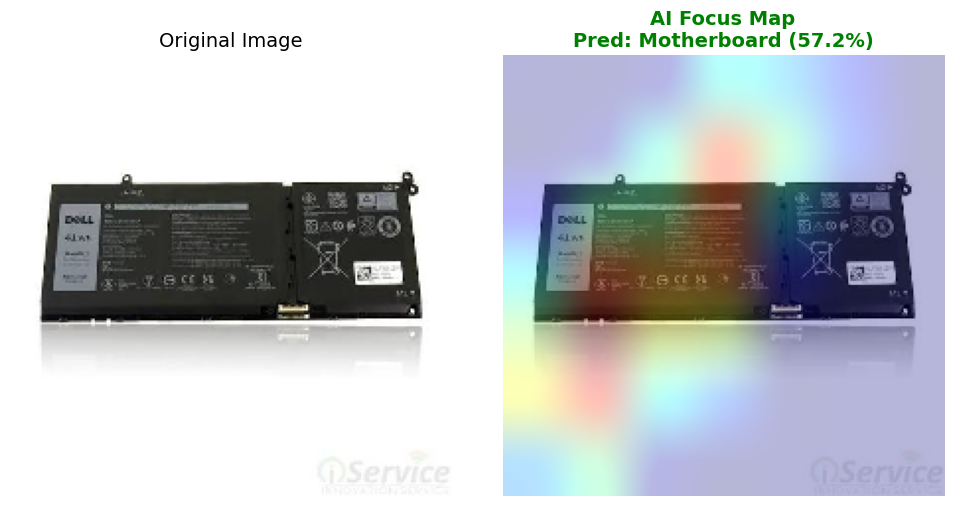

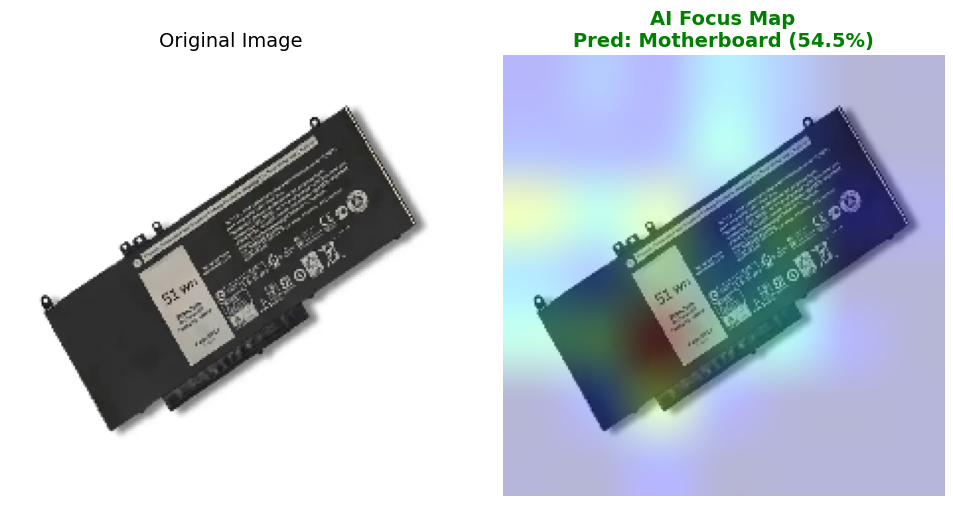

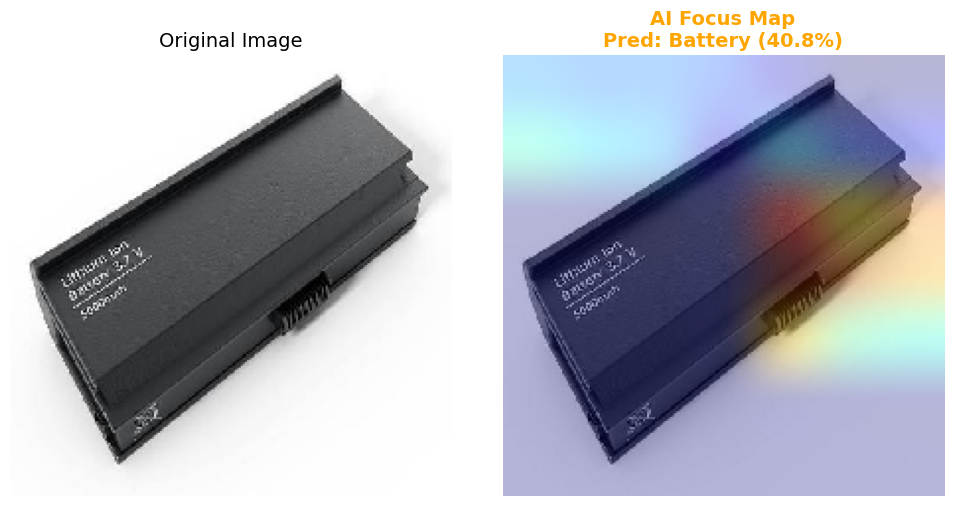

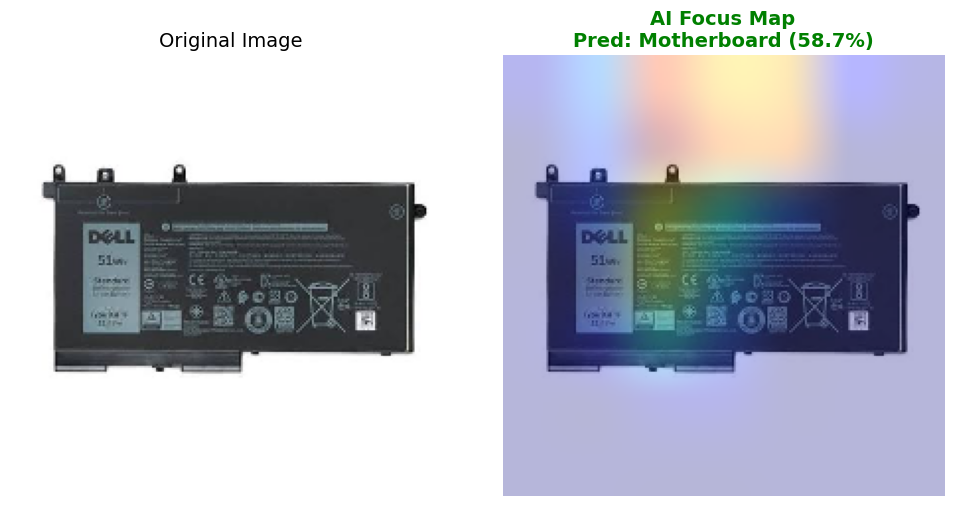

In [51]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image
from google.colab import files
import matplotlib.cm as cm

# 1. Find the last convolutional layer right before the GlobalAveragePooling layer
last_conv_layer_name = None

for layer in opt_densenet_model.layers:
    if layer.name == "gap":
        break

    last_conv_layer_name = layer.name

# 2. Build a Grad-CAM model that outputs both
#    the predictions AND the feature map
grad_model = tf.keras.models.Model(
    inputs=[opt_densenet_model.inputs],
    outputs=[
        opt_densenet_model.get_layer(
            last_conv_layer_name
        ).output,
        opt_densenet_model.output
    ]
)


def make_gradcam_heatmap(
    img_array,
    grad_model,
    pred_index=None
):
    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(
            img_array
        )

        if pred_index is None:
            pred_index = tf.argmax(preds[0])

        class_channel = preds[:, pred_index]

    # Calculate gradients of the top predicted class
    # with regard to the feature map
    grads = tape.gradient(
        class_channel,
        last_conv_layer_output
    )

    # Average the gradients spatially
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Multiply each channel in the feature map array
    # by how important this channel is
    last_conv_layer_output = last_conv_layer_output[0]

    heatmap = (
        last_conv_layer_output
        @ pooled_grads[..., tf.newaxis]
    )

    heatmap = tf.squeeze(heatmap)

    # Normalize the heatmap between 0 and 1
    heatmap = (
        tf.maximum(heatmap, 0)
        / tf.math.reduce_max(heatmap)
    )

    return (
        heatmap.numpy(),
        preds[0],
        pred_index
    )


print(
    "Upload an image to generate an AI Attention Heatmap:"
)

uploaded = files.upload()

for filename in uploaded.keys():

    # Load and prep image
    img = image.load_img(
        filename,
        target_size=IMAGE_SIZE
    )

    img_array = image.img_to_array(img)

    img_batch = np.expand_dims(
        img_array,
        axis=0
    )

    # Generate Heatmap
    heatmap, preds, top_idx = make_gradcam_heatmap(
        img_batch,
        grad_model
    )

    pred_class = TARGET_CLASSES[top_idx]
    confidence = preds[top_idx] * 100

    # Rescale heatmap to a range 0-255
    heatmap_rescaled = np.uint8(
        255 * heatmap
    )

    # Use jet colormap to colorize heatmap
    jet = cm.get_cmap("jet")

    jet_colors = jet(
        np.arange(256)
    )[:, :3]

    jet_heatmap = jet_colors[
        heatmap_rescaled
    ]

    # Superimpose the heatmap onto original image
    jet_heatmap = (
        tf.keras.preprocessing.image
        .array_to_img(jet_heatmap)
    )

    jet_heatmap = jet_heatmap.resize(
        (
            img_array.shape[1],
            img_array.shape[0]
        )
    )

    jet_heatmap = (
        tf.keras.preprocessing.image
        .img_to_array(jet_heatmap)
    )

    # Blend original and heatmap
    superimposed_img = (
        jet_heatmap * 0.4
        + img_array
    )

    superimposed_img = (
        tf.keras.preprocessing.image
        .array_to_img(superimposed_img)
    )

    # Plotting
    plt.figure(figsize=(10, 5))

    # Original Image
    ax1 = plt.subplot(1, 2, 1)

    ax1.imshow(img)
    ax1.axis("off")

    ax1.set_title(
        "Original Image",
        fontsize=14
    )

    # Heatmap Image
    ax2 = plt.subplot(1, 2, 2)

    ax2.imshow(superimposed_img)
    ax2.axis("off")

    color = (
        "green"
        if confidence > 50
        else "orange"
    )

    ax2.set_title(
        f"AI Focus Map\n"
        f"Pred: {pred_class} ({confidence:.1f}%)",
        fontsize=14,
        color=color,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

# Appendix: Exploratory & Checkup Scripts

In [ ]:
# -------------------------------------------------------------------------
# APPENDIX A: Data Leakage Check (Perceptual Hashing)
# -------------------------------------------------------------------------
def hash_all_images(base_dir, splits):
    records = []
    for split in splits:
        split_dir = os.path.join(base_dir, split)
        if not os.path.exists(split_dir): continue
        for class_name in os.listdir(split_dir):
            class_dir = os.path.join(split_dir, class_name)
            if not os.path.isdir(class_dir): continue
            for fname in os.listdir(class_dir):
                fpath = os.path.join(class_dir, fname)
                try:
                    phash = imagehash.phash(Image.open(fpath).convert("RGB"))
                    records.append({"split": split, "class": class_name, "filename": fname, "path": fpath, "hash": phash})
                except Exception as e: print(f"Error {fpath}: {e}")
    return records

def find_cross_split_matches(records, hash_distance_threshold=5):
    matches = []
    n = len(records)
    for i in range(n):
        for j in range(i + 1, n):
            r1, r2 = records[i], records[j]
            if r1["split"] == r2["split"]: continue
            distance = r1["hash"] - r2["hash"]
            if distance <= hash_distance_threshold:
                matches.append({"distance": distance, "split_1": r1["split"], "file_1": r1["filename"], "split_2": r2["split"], "file_2": r2["filename"]})
    return matches

print("Hashing images...")
records = hash_all_images(BASE_OUTPUT_DIR, SPLITS)
matches = find_cross_split_matches(records, 5)

if not matches:
    print("✅ No cross-split leakage found.")
else:
    print(f"⚠️ Found {len(matches)} suspicious cross-split matches:")
    for m in sorted(matches, key=lambda x: x["distance"])[:10]:
        print(f"  dist={m['distance']} | {m['split_1']}/{m['file_1']} <--> {m['split_2']}/{m['file_2']}")


In [ ]:
# -------------------------------------------------------------------------
# APPENDIX B: Dataset Deduplication & Crop Visualization
# -------------------------------------------------------------------------
# SUMMARY: Deduplicates the RAW source dataset (before ETL/split).
# Groups near-identical images into clusters using perceptual hashing, then keeps
# only the sharpest image per cluster (via Laplacian variance).

import os
import shutil
import cv2
import random
import numpy as np
from PIL import Image
import imagehash
import matplotlib.pyplot as plt

# ---- CONFIG ----
RAW_SOURCE_DIR = "/content/mendeley_raw_data/Laptop Components Image Dataset to Classify Different Components/Raw Data/Raw Data"
DEDUP_OUTPUT_DIR = "/content/deduplicated_raw_data_3"
REMOVED_DUPES_DIR = "/content/removed_duplicates_for_review_3"
CROP_DEBUG_DIR = "/content/crop_debug_3"
HASH_DISTANCE_THRESHOLD = 5
SAVE_CROP_DEBUG_IMAGES = True

TARGET_RAW_DIRS = [
    "5. Motherboard",
    "1. Battery",
    "8. RAM",
    "11. WifiCard",
    "20. CPUFan",
]

CROP_FRACTIONS = {
    "5. Motherboard": (0.70, 0.70),
    "1. Battery":     (0.55, 0.55),
    "8. RAM":         (0.30, 0.30),
    "20. CPUFan":     (0.45, 0.45),
}
DEFAULT_CROP_FRACTION = (0.5, 0.5)

DETECTION_BASED_CLASSES = {"11. WifiCard"}
SATURATION_THRESHOLD = 35
MIN_OBJECT_AREA_FRACTION = 0.0005
MAX_OBJECT_AREA_FRACTION = 0.90
DETECTION_MARGIN_MULTIPLIER = 1.5
DETECTION_FALLBACK_CROP_FRACTION = (0.35, 0.35)

os.makedirs(DEDUP_OUTPUT_DIR, exist_ok=True)
os.makedirs(REMOVED_DUPES_DIR, exist_ok=True)
if SAVE_CROP_DEBUG_IMAGES:
    os.makedirs(CROP_DEBUG_DIR, exist_ok=True)

# ---- HELPER FUNCTIONS ----
def center_crop(image_bgr, width_fraction, height_fraction):
    h, w = image_bgr.shape[:2]
    crop_w = max(1, int(w * width_fraction))
    crop_h = max(1, int(h * height_fraction))
    x0 = (w - crop_w) // 2
    y0 = (h - crop_h) // 2
    return image_bgr[y0:y0 + crop_h, x0:x0 + crop_w]

def detect_object_bbox_by_saturation(image_bgr):
    h_img, w_img = image_bgr.shape[:2]
    total_area = h_img * w_img
    hsv = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2HSV)
    saturation = hsv[:, :, 1]
    _, mask = cv2.threshold(saturation, SATURATION_THRESHOLD, 255, cv2.THRESH_BINARY)
    kernel = np.ones((3, 3), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel, iterations=2)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel, iterations=1)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours: return None
    largest = max(contours, key=cv2.contourArea)
    area = cv2.contourArea(largest)
    area_fraction = area / total_area
    if area_fraction < MIN_OBJECT_AREA_FRACTION or area_fraction > MAX_OBJECT_AREA_FRACTION: return None
    return cv2.boundingRect(largest)

def crop_via_saturation_detection(image_bgr, fallback_fraction):
    h_img, w_img = image_bgr.shape[:2]
    bbox = detect_object_bbox_by_saturation(image_bgr)
    if bbox is None: return center_crop(image_bgr, *fallback_fraction), False
    x, y, w, h = bbox
    margin_x = int(w * DETECTION_MARGIN_MULTIPLIER)
    margin_y = int(h * DETECTION_MARGIN_MULTIPLIER)
    x0 = max(0, x - margin_x)
    y0 = max(0, y - margin_y)
    x1 = min(w_img, x + w + margin_x)
    y1 = min(h_img, y + h + margin_y)
    return image_bgr[y0:y1, x0:x1], True

def laplacian_variance_gray(gray_img):
    return cv2.Laplacian(gray_img, cv2.CV_64F).var()

def hash_class_images(class_dir, class_name):
    records = []
    debug_dir = os.path.join(CROP_DEBUG_DIR, class_name) if SAVE_CROP_DEBUG_IMAGES else None
    if debug_dir: os.makedirs(debug_dir, exist_ok=True)
    use_detection = class_name in DETECTION_BASED_CLASSES
    width_fraction, height_fraction = CROP_FRACTIONS.get(class_name, DEFAULT_CROP_FRACTION)
    fallback_count = 0

    for fname in os.listdir(class_dir):
        fpath = os.path.join(class_dir, fname)
        if not os.path.isfile(fpath): continue
        try:
            image_bgr = cv2.imread(fpath)
            if image_bgr is None: continue

            if use_detection:
                cropped_bgr, was_detected = crop_via_saturation_detection(image_bgr, DETECTION_FALLBACK_CROP_FRACTION)
                if not was_detected: fallback_count += 1
            else:
                cropped_bgr = center_crop(image_bgr, width_fraction, height_fraction)

            cropped_gray = cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2GRAY)
            sharpness = laplacian_variance_gray(cropped_gray)
            phash = imagehash.phash(Image.fromarray(cv2.cvtColor(cropped_bgr, cv2.COLOR_BGR2RGB)))

            if debug_dir: cv2.imwrite(os.path.join(debug_dir, fname), cropped_bgr)
            records.append({"filename": fname, "path": fpath, "hash": phash, "sharpness": sharpness})
        except Exception as e: print(f"Could not process {fpath}: {e}")
    return records

def cluster_by_hash(records, threshold):
    n = len(records)
    parent = list(range(n))
    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(x, y):
        rx, ry = find(x), find(y)
        if rx != ry: parent[ry] = rx

    for i in range(n):
        for j in range(i + 1, n):
            if records[i]["hash"] - records[j]["hash"] <= threshold: union(i, j)

    clusters = {}
    for i in range(n):
        clusters.setdefault(find(i), []).append(records[i])
    return list(clusters.values())

def dedupe_class(class_name, class_dir):
    mode = "saturation-DETECTION" if class_name in DETECTION_BASED_CLASSES else "fixed center-crop"
    print(f"\nProcessing class: {class_name}  ({mode})")
    records = hash_class_images(class_dir, class_name)
    clusters = cluster_by_hash(records, HASH_DISTANCE_THRESHOLD)

    out_class_dir = os.path.join(DEDUP_OUTPUT_DIR, class_name)
    removed_class_dir = os.path.join(REMOVED_DUPES_DIR, class_name)
    os.makedirs(out_class_dir, exist_ok=True)
    os.makedirs(removed_class_dir, exist_ok=True)

    kept, removed = 0, 0
    for cluster in clusters:
        cluster_sorted = sorted(cluster, key=lambda r: r["sharpness"], reverse=True)
        best = cluster_sorted[0]
        shutil.copy2(best["path"], os.path.join(out_class_dir, best["filename"]))
        kept += 1
        for dup in cluster_sorted[1:]:
            shutil.copy2(dup["path"], os.path.join(removed_class_dir, dup["filename"]))
            removed += 1

    return kept, removed

# ---- EXECUTE DEDUPLICATION ----
summary = {}
if os.path.exists(RAW_SOURCE_DIR):
    for class_name in TARGET_RAW_DIRS:
        class_dir = os.path.join(RAW_SOURCE_DIR, class_name)
        if os.path.isdir(class_dir):
            kept, removed = dedupe_class(class_name, class_dir)
            summary[class_name] = {"kept": kept, "removed": removed}

print("\n===== SUMMARY =====")
for class_name, counts in summary.items():
    print(f"{class_name:15s}: {counts['kept']:3d} unique / {counts['kept'] + counts['removed']:3d} raw")

# -------------------------------------------------------------------------
# CROP VISUALIZATION TOOL
# -------------------------------------------------------------------------
def load_image_rgb(path):
    img_bgr = cv2.imread(path)
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB) if img_bgr is not None else None

def show_original_vs_cropped(class_name, samples_per_class=5):
    original_dir = os.path.join(RAW_SOURCE_DIR, class_name)
    cropped_dir = os.path.join(CROP_DEBUG_DIR, class_name)

    if not os.path.exists(original_dir) or not os.path.exists(cropped_dir): return

    common_files = sorted(set(os.listdir(original_dir)) & set(os.listdir(cropped_dir)))
    if not common_files: return

    sample_files = random.sample(common_files, min(samples_per_class, len(common_files)))

    sets_per_row = 3
    num_rows = (len(sample_files) + sets_per_row - 1) // sets_per_row

    fig, axes = plt.subplots(num_rows, sets_per_row * 2, figsize=(18, 5 * num_rows))
    axes = np.atleast_2d(axes)
    fig.suptitle(f"Original vs. Cropped — {class_name}", fontsize=16, fontweight="bold")

    for i, fname in enumerate(sample_files):
        set_row, set_pos = i // sets_per_row, i % sets_per_row
        orig_col, crop_col = set_pos * 2, set_pos * 2 + 1

        orig_img = load_image_rgb(os.path.join(original_dir, fname))
        crop_img = load_image_rgb(os.path.join(cropped_dir, fname))

        if orig_img is not None:
            axes[set_row][orig_col].imshow(orig_img)
            axes[set_row][orig_col].set_title(f"Normal\n{fname}", fontsize=9)
        axes[set_row][orig_col].axis("off")

        if crop_img is not None:
            axes[set_row][crop_col].imshow(crop_img)
            axes[set_row][crop_col].set_title("Crop", fontsize=9)
        axes[set_row][crop_col].axis("off")

    plt.tight_layout()
    plt.show()

# Run visualizations
for class_name in TARGET_RAW_DIRS:
    show_original_vs_cropped(class_name, 5)